# XGBoost — Final Model

Predicting Massive Transfusion (MT) in trauma patients using early clinical parameters.

In [31]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score, classification_report, confusion_matrix, roc_curve,
    precision_score, recall_score, f1_score, average_precision_score
)

## 1. Load Data

In [32]:
# Load preprocessed data
with open('preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X_train = data['X_train']
X_test = data['X_test']
y_train = data['y_train']
y_test = data['y_test']
scaler = data['scaler']

# Setup: class imbalance weight and CV strategy
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Data loaded!")
print(f"scale_pos_weight: {scale_pos_weight:.2f}")
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Data loaded!
scale_pos_weight: 3.00
Train shape: (800, 9), Test shape: (200, 9)


## 2. Baseline Model

Default XGBoost parameters, threshold = 0.50.

In [33]:
# Baseline XGBoost — default parameters
xgb_baseline = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)

xgb_baseline.fit(X_train, y_train)

y_pred_baseline = xgb_baseline.predict(X_test)
y_proba_baseline = xgb_baseline.predict_proba(X_test)[:, 1]

print("=== Baseline XGBoost (threshold=0.50) ===")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_baseline):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_proba_baseline):.3f}")
print()
print(classification_report(y_test, y_pred_baseline, target_names=['Non-MT', 'MT']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

=== Baseline XGBoost (threshold=0.50) ===
ROC-AUC: 0.888
PR-AUC:  0.773

              precision    recall  f1-score   support

      Non-MT       0.88      0.86      0.87       150
          MT       0.61      0.66      0.63        50

    accuracy                           0.81       200
   macro avg       0.75      0.76      0.75       200
weighted avg       0.82      0.81      0.81       200

Confusion Matrix:
[[129  21]
 [ 17  33]]


## 3. Hyperparameter Tuning (GridSearchCV)

Search for the best parameters, optimizing PR-AUC (better than ROC-AUC for imbalanced classes).

In [34]:
# GridSearchCV — search best parameters
param_grid = {
    'max_depth': [2, 3, 4],
    'learning_rate': [0.01, 0.05, 0.1],
    'min_child_weight': [1, 3, 5, 7],
    'subsample': [0.7, 0.8, 0.9, 1.0]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='logloss'
    ),
    param_grid=param_grid,
    scoring='average_precision',  # PR-AUC
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print(f"Best CV PR-AUC: {grid_search.best_score_:.3f}")

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 1.0}
Best CV PR-AUC: 0.820


## 4. Train Tuned Model

Using the best parameters found by GridSearchCV.

In [35]:
# Train model with best GridSearchCV parameters
xgb_tuned = XGBClassifier(
    **grid_search.best_params_,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)

xgb_tuned.fit(X_train, y_train)

y_pred_tuned = xgb_tuned.predict(X_test)
y_proba_tuned = xgb_tuned.predict_proba(X_test)[:, 1]

print("=== Tuned XGBoost (threshold=0.50) ===")
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_tuned):.3f}")
print(f"PR-AUC:  {average_precision_score(y_test, y_proba_tuned):.3f}")
print()
print(classification_report(y_test, y_pred_tuned, target_names=['Non-MT', 'MT']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

=== Tuned XGBoost (threshold=0.50) ===
ROC-AUC: 0.902
PR-AUC:  0.791

              precision    recall  f1-score   support

      Non-MT       0.91      0.85      0.88       150
          MT       0.63      0.76      0.69        50

    accuracy                           0.83       200
   macro avg       0.77      0.81      0.79       200
weighted avg       0.84      0.83      0.83       200

Confusion Matrix:
[[128  22]
 [ 12  38]]


## 5. Threshold Optimization (Out-of-Fold)

The default threshold of 0.50 is rarely optimal. We select the threshold on **training data only** using out-of-fold (OOF) cross-validation predictions — this avoids leaking information from the test set.

Clinical requirement: **Recall ≥ 0.80** (do not miss MT patients), then maximize F1 among qualifying thresholds.

In [36]:
# Get OOF probabilities on TRAIN (no test leakage)
oof_proba = cross_val_predict(
    xgb_tuned, X_train, y_train, cv=cv, method='predict_proba'
)[:, 1]

print(f"OOF ROC-AUC on train: {roc_auc_score(y_train, oof_proba):.3f}")
print()

# Build threshold table
threshold_results = []
for t in np.arange(0.10, 0.91, 0.01):
    y_oof_pred = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, y_oof_pred).ravel()
    
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    precision = precision_score(y_train, y_oof_pred, zero_division=0)
    f1 = f1_score(y_train, y_oof_pred, zero_division=0)
    
    threshold_results.append({
        'threshold': round(t, 2), 'recall': recall,
        'specificity': specificity, 'precision': precision, 'f1': f1
    })

threshold_df = pd.DataFrame(threshold_results)

print("Top 10 thresholds by F1:")
print(threshold_df.sort_values('f1', ascending=False).head(10).to_string(index=False))
print()

# Select threshold: max F1 among those with Recall >= 0.80
candidates = threshold_df[threshold_df['recall'] >= 0.80]
if len(candidates) > 0:
    best_row = candidates.sort_values('f1', ascending=False).iloc[0]
    print("Selected threshold (Recall >= 0.80, max F1):")
else:
    best_row = threshold_df.sort_values('f1', ascending=False).iloc[0]
    print("No threshold met Recall >= 0.80. Selected by max F1:")

selected_threshold = best_row['threshold']

print(f"Threshold:   {selected_threshold:.2f}")
print(f"Recall:      {best_row['recall']:.3f}")
print(f"Specificity: {best_row['specificity']:.3f}")
print(f"Precision:   {best_row['precision']:.3f}")
print(f"F1:          {best_row['f1']:.3f}")

OOF ROC-AUC on train: 0.914

Top 10 thresholds by F1:
 threshold  recall  specificity  precision       f1
      0.44   0.800     0.848333   0.637450 0.709534
      0.48   0.775     0.863333   0.654008 0.709382
      0.47   0.780     0.860000   0.650000 0.709091
      0.45   0.795     0.850000   0.638554 0.708241
      0.46   0.785     0.855000   0.643443 0.707207
      0.40   0.825     0.830000   0.617978 0.706638
      0.43   0.805     0.841667   0.628906 0.706140
      0.41   0.820     0.831667   0.618868 0.705376
      0.49   0.760     0.868333   0.658009 0.705336
      0.51   0.745     0.876667   0.668161 0.704492

Selected threshold (Recall >= 0.80, max F1):
Threshold:   0.44
Recall:      0.800
Specificity: 0.848
Precision:   0.637
F1:          0.710


## 6. Final Evaluation on Test Set

Apply the selected threshold (chosen on train) to the held-out test set.

In [37]:
# Apply selected threshold to test set
test_proba = xgb_tuned.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()

print("=== FINAL XGBoost — Test Results ===")
print(f"Parameters: {grid_search.best_params_}")
print(f"Threshold:  {selected_threshold:.2f} (OOF-selected)")
print()
print(f"ROC-AUC:     {roc_auc_score(y_test, test_proba):.3f}")
print(f"PR-AUC:      {average_precision_score(y_test, test_proba):.3f}")
print(f"Recall:      {tp/(tp+fn):.3f}")
print(f"Specificity: {tn/(tn+fp):.3f}")
print(f"Precision:   {precision_score(y_test, test_pred):.3f}")
print(f"F1:          {f1_score(y_test, test_pred):.3f}")
print()
print(classification_report(y_test, test_pred, target_names=['Non-MT', 'MT']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, test_pred))

=== FINAL XGBoost — Test Results ===
Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 1.0}
Threshold:  0.44 (OOF-selected)

ROC-AUC:     0.902
PR-AUC:      0.791
Recall:      0.800
Specificity: 0.833
Precision:   0.615
F1:          0.696

              precision    recall  f1-score   support

      Non-MT       0.93      0.83      0.88       150
          MT       0.62      0.80      0.70        50

    accuracy                           0.82       200
   macro avg       0.77      0.82      0.79       200
weighted avg       0.85      0.82      0.83       200

Confusion Matrix:
[[125  25]
 [ 10  40]]


## 7. Visualizations

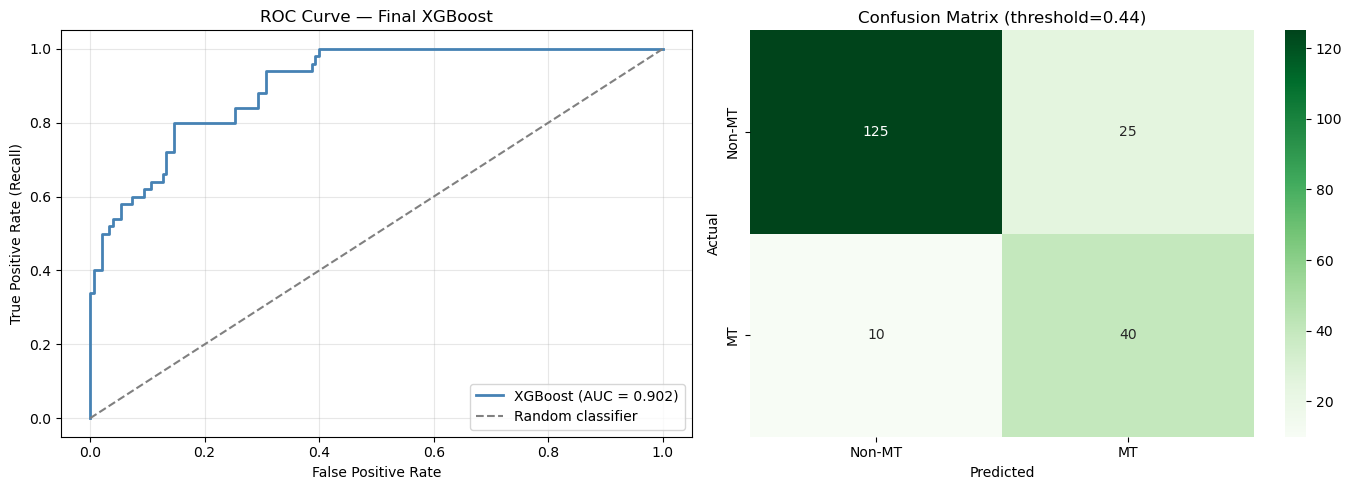

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[0].plot(fpr, tpr, color='steelblue', linewidth=2,
             label=f"XGBoost (AUC = {roc_auc_score(y_test, test_proba):.3f})")
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].set_title('ROC Curve — Final XGBoost')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Confusion Matrix
cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Non-MT', 'MT'], yticklabels=['Non-MT', 'MT'], ax=axes[1])
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_title(f'Confusion Matrix (threshold={selected_threshold:.2f})')

plt.tight_layout()
plt.show()

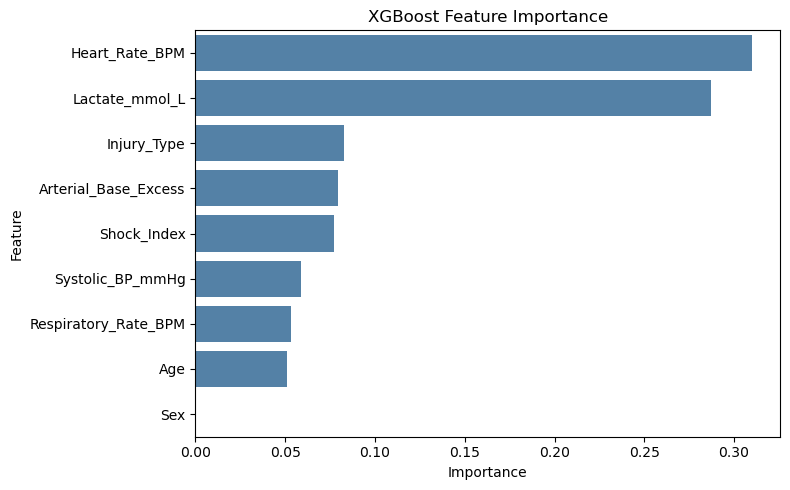

             Feature  Importance
      Heart_Rate_BPM    0.310079
      Lactate_mmol_L    0.287393
         Injury_Type    0.082987
Arterial_Base_Excess    0.079443
         Shock_Index    0.077305
    Systolic_BP_mmHg    0.058800
Respiratory_Rate_BPM    0.053042
                 Age    0.050950
                 Sex    0.000000


In [39]:
# Feature Importance
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_tuned.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance, x='Importance', y='Feature', color='steelblue')
plt.title('XGBoost Feature Importance')
plt.tight_layout()
plt.show()

print(importance.to_string(index=False))

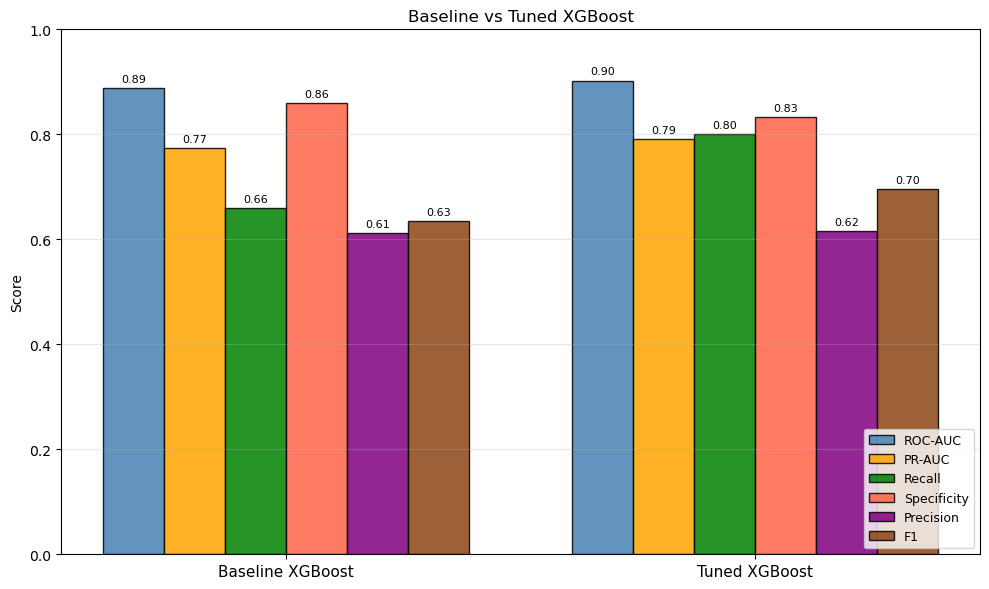

In [43]:
# ── Baseline vs Tuned XGBoost — Bar Chart ──
metrics = ['ROC-AUC', 'PR-AUC', 'Recall', 'Specificity', 'Precision', 'F1']
colors = ['steelblue', 'orange', 'green', 'tomato', 'purple', 'saddlebrown']

x = np.arange(2)
width = 0.13

fig, ax = plt.subplots(figsize=(10, 6))

for j, (metric, color) in enumerate(zip(metrics, colors)):
    values = comparison[metric].values
    bars = ax.bar(x + j * width - 2.5 * width, values, width,
                  label=metric, color=color, alpha=0.85, edgecolor='black')
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
                f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(['Baseline XGBoost', 'Tuned XGBoost'], fontsize=11)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.0)
ax.set_title('Baseline vs Tuned XGBoost')
ax.legend(loc='lower right', fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Baseline vs Tuned Comparison

In [40]:
def get_specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

comparison = pd.DataFrame({
    'Model': ['Baseline (thr=0.50)', 'Tuned (thr=%.2f)' % selected_threshold],
    'ROC-AUC': [roc_auc_score(y_test, y_proba_baseline), roc_auc_score(y_test, test_proba)],
    'PR-AUC': [average_precision_score(y_test, y_proba_baseline), average_precision_score(y_test, test_proba)],
    'Recall': [recall_score(y_test, y_pred_baseline), recall_score(y_test, test_pred)],
    'Specificity': [get_specificity(y_test, y_pred_baseline), get_specificity(y_test, test_pred)],
    'Precision': [precision_score(y_test, y_pred_baseline), precision_score(y_test, test_pred)],
    'F1': [f1_score(y_test, y_pred_baseline), f1_score(y_test, test_pred)]
})

display(comparison.round(3))

,Model,ROC-AUC,PR-AUC,Recall,Specificity,Precision,F1
0,Baseline (thr=0.50),0.888,0.773,0.66,0.860,0.611,0.635
1,Tuned (thr=0.44),0.902,0.791,0.80,0.833,0.615,0.696


## 9. Clinical Baseline — ABC Score

Simplified ABC Score (without FAST): Penetrating injury + SBP ≤ 90 + HR ≥ 120. Predicts MT if score ≥ 2.

In [41]:
# Simplified ABC Score (without FAST)
ABC_score = (
    (X_test['Injury_Type'] == 1).astype(int) +
    (X_test['Systolic_BP_mmHg'] <= 90).astype(int) +
    (X_test['Heart_Rate_BPM'] >= 120).astype(int)
)
ABC_pred = (ABC_score >= 2).astype(int)

print("=== ABC Score (baseline) ===")
print(f"ROC-AUC: {roc_auc_score(y_test, ABC_score):.3f}")
print()
print(classification_report(y_test, ABC_pred, target_names=['Non-MT', 'MT']))
print("Confusion Matrix:")
print(confusion_matrix(y_test, ABC_pred))

# Comparison
abc_comparison = pd.DataFrame({
    'Model': ['ABC Score', 'XGBoost (final)'],
    'ROC-AUC': [roc_auc_score(y_test, ABC_score), roc_auc_score(y_test, test_proba)],
    'Recall': [recall_score(y_test, ABC_pred), recall_score(y_test, test_pred)],
    'Precision': [precision_score(y_test, ABC_pred), precision_score(y_test, test_pred)],
    'F1': [f1_score(y_test, ABC_pred), f1_score(y_test, test_pred)],
    'Specificity': [get_specificity(y_test, ABC_pred), get_specificity(y_test, test_pred)]
})
print()
display(abc_comparison.round(3))

=== ABC Score (baseline) ===
ROC-AUC: 0.747

              precision    recall  f1-score   support

      Non-MT       0.83      0.99      0.90       150
          MT       0.90      0.38      0.54        50

    accuracy                           0.83       200
   macro avg       0.87      0.68      0.72       200
weighted avg       0.85      0.83      0.81       200

Confusion Matrix:
[[148   2]
 [ 31  19]]



,Model,ROC-AUC,Recall,Precision,F1,Specificity
0,ABC Score,0.747,0.38,0.905,0.535,0.987
1,XGBoost (final),0.902,0.80,0.615,0.696,0.833


## 10. Testing on New Patients

In [42]:
def predict_patient(patient_dict):
    patient = pd.DataFrame([patient_dict])[X_train.columns]
    proba = xgb_tuned.predict_proba(patient)[:, 1][0]
    pred = int(proba >= selected_threshold)
    
    print(f"Probability of MT: {proba:.3f}")
    print(f"Threshold: {selected_threshold:.2f}")
    if pred == 1:
        print("=> HIGH risk of Massive Transfusion")
        print("   Consider early activation of Massive Transfusion Protocol (MTP).")
    else:
        print("=> LOW risk of Massive Transfusion")
    print()

# Stable patient
print("--- Patient 1 (stable) ---")
predict_patient({
    'Age': 34, 'Sex': 1, 'Systolic_BP_mmHg': 120, 'Heart_Rate_BPM': 81,
    'Respiratory_Rate_BPM': 12, 'Injury_Type': 1, 'Lactate_mmol_L': 1.22,
    'Arterial_Base_Excess': -2.0, 'Shock_Index': 0.67
})

# Higher-risk patient
print("--- Patient 2 (borderline) ---")
predict_patient({
    'Age': 18, 'Sex': 0, 'Systolic_BP_mmHg': 90, 'Heart_Rate_BPM': 110,
    'Respiratory_Rate_BPM': 16, 'Injury_Type': 1, 'Lactate_mmol_L': 3.22,
    'Arterial_Base_Excess': -2.0, 'Shock_Index': 1.22
})

--- Patient 1 (stable) ---
Probability of MT: 0.016
Threshold: 0.44
=> LOW risk of Massive Transfusion

--- Patient 2 (borderline) ---
Probability of MT: 0.597
Threshold: 0.44
=> HIGH risk of Massive Transfusion
   Consider early activation of Massive Transfusion Protocol (MTP).



## Conclusion

**Final Model: XGBoost (GridSearchCV-tuned, OOF F1-optimal threshold)**

| Metric | Baseline (thr=0.50) | Final (thr=0.44) | ABC Score |
|--------|--------------------|--------------------|-----------|
| ROC-AUC | 0.888 | **0.902** | 0.747 |
| PR-AUC | 0.773 | **0.791** | — |
| Recall MT | 0.66 | **0.80** | 0.38 |
| Precision MT | 0.61 | 0.62 | **0.90** |
| F1 MT | 0.635 | **0.70** | 0.54 |

**Key findings:**
- GridSearchCV (optimizing PR-AUC) found best parameters: max_depth=3, learning_rate=0.1, min_child_weight=1, subsample=1.0
- Threshold was selected on out-of-fold training predictions (not on test) to avoid data leakage
- Clinical constraint applied: Recall ≥ 0.80, then maximize F1 → threshold = 0.44
- Final model finds 40 of 50 MT patients (80% recall), only 10 missed
- XGBoost substantially outperforms the ABC Score baseline in Recall (0.80 vs 0.38) and F1 (0.70 vs 0.54)
- ABC Score has high Precision (0.90) but misses 62% of MT patients — unsuitable as a standalone screening tool

**Limitations:**
- Synthetic dataset with an intentional gray zone (~43% overlapping cases)
- Performance on real clinical data may differ

**Next steps:**
- Validate on real institutional dataset
- Ablation study (with/without Lactate)

*Note: This model is a clinical decision-support tool and should complement, not replace, physician judgment.*